# Frecuencia y amplitud de componentes armónicas de una señal y su frecuencia: $x(t) = \sum_i^n b_i \sin(2\pi f_i t)$ o $x(t) = \sum_i^n a_i \cos(2\pi f_i t)$ (no nos responsabilizamos por daños por su uso)

#### Ejemplo. Para determinar la frecuencia y amplitud de sus componentes armónicas, y frecuencia de la señal: 

#### $x(t) =  3 \sin(100\pi t) -4 \sin(200\pi t) + 0.7\sin(300\pi t)$

#### Ordenemos (si no lo está) las componentes de menor a mayor frecuencia, y expresemos los ángulos en la forma: $2\pi f_i t$, a fin de determinar la frecuencia $f_i$ y tipo de armónica presente.

#### $x(t) =  3 \sin(2\pi 50t) -4 \sin(2\pi 100t) + 0.7\sin(2\pi 150t) $

#### Ingresemos sus amplitudes y frecuencias presentes en las listas o vectores.

In [8]:
# Ingreso de frecuencias y coeficientes de x(t)
# 2*2*19pi= 76pi, 2*3*19pi= 114pi,   2*19*5pi= 190pi
frecs = [50, 100,  150 ] #[50, 100, 150]          # ingrese las frecuencias de menor a mayor
coeficientes = [3, -4, 0.7] #[3, -4, 0.7]     # ingrese los coeficientes según frecuencias correspondientes

#### Vemos que la señal contiene componentes a $50, 100$ y $150$ Hz. Para determinar la frecuencia $f$ de la señal, determinemos el MAXIMO COMUN DIVISOR, de las frecuencias de cada una de sus componentes. Usemos los códigos siguientes (o bien encuentre por inspección):

In [9]:
def find_gcd(x, y): 
    while(y): 
        x, y = y, x % y   
    return x 
  
num1=frecs[0] 
num2=frecs[1] 
gcd=find_gcd(num1,num2) 
  
for i in range(2,len(frecs)): 
    gcd=find_gcd(gcd,frecs[i]) 
f = gcd 
print('f = %d Hz'%(f))
  
# Code contributed by Mohit Gupta_OMG

f = 50 Hz


#### En este caso la frecuencia de la señal es $f = 50$ Hz. Para derminar el tipo de armónica de cada componente, calculemos los cocientes, frecuencia de cada componente entre $f$ 

In [14]:
armonicas = [k/f for k in frecs]
for i in range(len(frecs)):
    print ('%5d, %d'%(frecs[i], armonicas[i]))

   50, 1
  100, 2
  150, 3


#### De aquí vemos que en la señal $x(t)$, la componente a $50$ Hz con amplitud $3$ es la fundamental, la componente a $100$ Hz con amplitud $|-4|=4$ es la segunda armónica y la componente a $150$ con amplitud $0.7$ Hz es la tercera armónica. La frecuencia de la señal es $f = 50$ Hz.

#### Si deseamos una construir una tablita que incluya las amplitudes y sus períodos, ingresemos el vector de amplitudes y podemos usar los códigos siguientes

In [11]:
print ('Amplitud  frecuencia Hz  período sg  armónica')
amplitudes = [abs(k) for k in coeficientes] 
periodos = [1./k for k in frecs]
for i in range(len(frecs)):
    print ('%5.1f %12d %14.3f %7d' %(amplitudes[i], frecs[i], periodos[i], armonicas[i]))

Amplitud  frecuencia Hz  período sg  armónica
  3.0           50          0.020       1
  4.0          100          0.010       2
  0.7          150          0.007       3


#### Podemos ver las grafica de las armónicas y de $x(t)$ para dos períodos de la fundamental con los códigos.

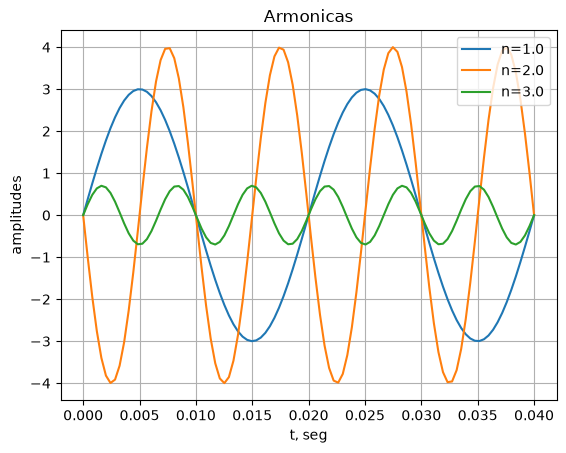

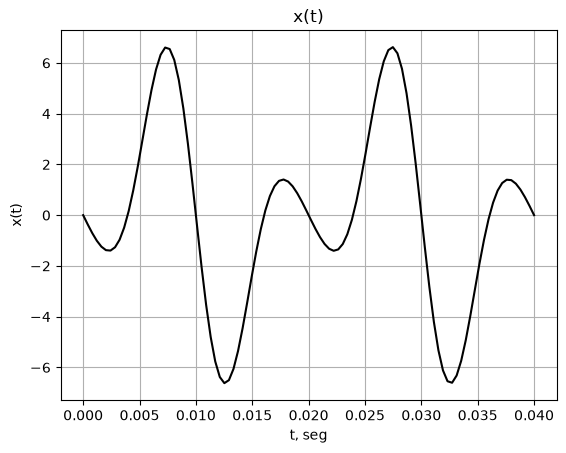

In [12]:
#Puede que necesite digitar dos veces shift-intro

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, g = plt.subplots() 
t = np.linspace(0, 2./f, 100)

for k in range(len(frecs)):
    g.plot(t, coeficientes[k]*np.sin(2*np.pi*frecs[k]*t), label="n={0}".format(armonicas[k]))
plt.xlabel('t, seg')
plt.ylabel('amplitudes')
plt.title('Armonicas')
plt.legend()
plt.grid(True)
plt.show()

s = [0]*100
for k in range(len(frecs)):
    t = np.linspace(0, 2./f, 100)
    sp = (coeficientes[k]*np.sin(2*np.pi*frecs[k]*t))
    s += sp
plt.plot(t, s, 'k')
plt.title('x(t)')
plt.xlabel('t, seg')
plt.ylabel('x(t)')
plt.grid(True)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

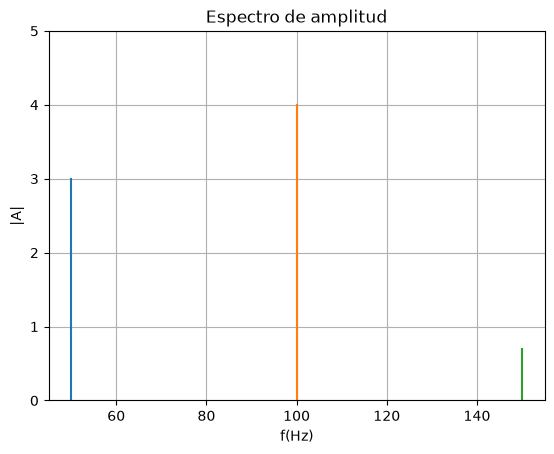

In [13]:
for i in range(len(frecs)):
    x = [[frecs[i], frecs[i]]]
    y = [[0, abs(coeficientes[i])]]
    plt.plot(x[0], y[0])
plt.title('Espectro de amplitud')
plt.xlabel('f(Hz)')
plt.ylabel('|A|')
plt.grid(True)
#plt.xlim(0,5)
plt.ylim(0,5)
plt.show